In [12]:
import os
import json
from PIL import Image

import torch
import torch.utils.data as data
import torchvision.transforms.v2 as tfs
import torch.nn as nn
import torch.optim as optim
from tqdm import tqdm

Урок в прозе: https://proproprogs.ru/nn_pytorch/pytorch-klassifikaciya-izobrazheniy-cifr-bd-mnist

https://github.com/selfedu-rus/neuro-pytorch/blob/main/neuro_net_20.py

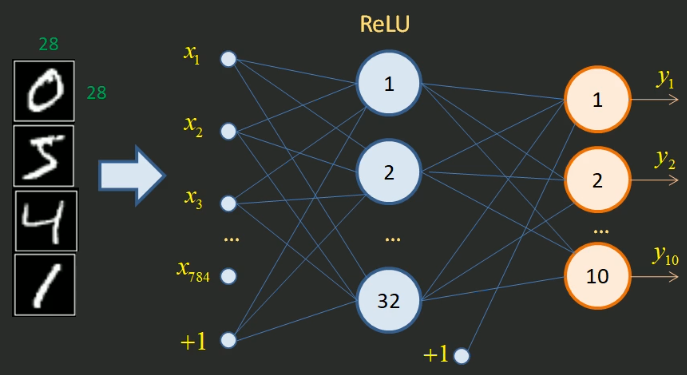

Мы не будем в конце использовать Softmax, так как он уже включен в функцию потерь CrossEntropyLoss

In [17]:
class DigitDataset(data.Dataset):
    def __init__(self, path, train=True, transform=None):
        self.path = os.path.join(path, "train" if train else "test")
        self.transform = transform

        with open(os.path.join(path, "format.json"), "r") as fp:
            self.format = json.load(fp)

        self.length = 0
        self.files = []
        self.targets = torch.eye(10)

        for _dir, _target in self.format.items():
            path = os.path.join(self.path, _dir)
            list_files = os.listdir(path)
            self.length += len(list_files)
            self.files.extend(map(lambda _x: (os.path.join(path, _x), _target), list_files))

    def __getitem__(self, item):
        path_file, target = self.files[item]
        t = self.targets[target]
        img = Image.open(path_file)

        if self.transform:
            img = self.transform(img).ravel().float() / 255.0

        return img, t

    def __len__(self):
        return self.length

In [18]:
class DigitNN(nn.Module):
    def __init__(self, input_dim, num_hidden, output_dim):
        super().__init__()
        self.layer1 = nn.Linear(input_dim, num_hidden)
        self.layer2 = nn.Linear(num_hidden, output_dim)

    def forward(self, x):
        x = self.layer1(x)
        x = nn.functional.relu(x)
        x = self.layer2(x)
        return x

In [19]:
model = DigitNN(28 * 28, 32, 10)

to_tensor = tfs.ToImage()  # PILToTensor
d_train = DigitDataset("dataset", transform=to_tensor)
train_data = data.DataLoader(d_train, batch_size=32, shuffle=True)

optimizer = optim.Adam(params=model.parameters(), lr=0.01)
loss_function = nn.CrossEntropyLoss()
epochs = 2
model.train()

for _e in range(epochs):
    loss_mean = 0
    lm_count = 0

    train_tqdm = tqdm(train_data, leave=True)
    for x_train, y_train in train_tqdm:
        predict = model(x_train)
        loss = loss_function(predict, y_train)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        lm_count += 1
        loss_mean = 1/lm_count * loss.item() + (1 - 1/lm_count) * loss_mean
        train_tqdm.set_description(f"Epoch [{_e+1}/{epochs}], loss_mean={loss_mean:.3f}")

Epoch [2/2], loss_mean=0.184: 100%|██████████| 1875/1875 [00:51<00:00, 36.45it/s]


In [21]:
d_test = DigitDataset("dataset", train=False, transform=to_tensor)
test_data = data.DataLoader(d_test, batch_size=500, shuffle=False)

Q = 0

# тестирование обученной НС
model.eval()

for x_test, y_test in test_data:
    with torch.no_grad():
        p = model(x_test)
        p = torch.argmax(p, dim=1)
        y = torch.argmax(y_test, dim=1)
        Q += torch.sum(p == y).item()

Q /= len(d_test)
print(Q)

0.9417
